# Порівняльний аналіз методів машинного навчання для задачі діагностики серцево-судинних захворювань

**Дисципліна:** Обробка надвеликих масивів даних

## Мета роботи

Дослідити, реалізувати та провести порівняльний аналіз різних методів машинного навчання для задачі бінарної класифікації ризику наявності серцево-судинних захворювань.

## Основні етапи

1. Завантаження та аналіз набору даних UCI Heart Disease.
2. Дослідницький аналіз даних (EDA).
3. Обробка пропущених значень та підготовка даних.
4. Розділення на тренувальну та тестову вибірки.
5. Масштабування числових ознак.
6. Навчання моделей:
   - логістична регресія;
   - метод опорних векторів;
   - випадковий ліс.
7. Порівняння моделей за метриками Accuracy, Precision, Recall, F1-Score та ROC-AUC.
8. Аналіз матриць плутанини та False Negative.
9. Вибір і збереження найкращої моделі.

### 1. Імпорт необхідних бібліотек

In [1]:
import os
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Бібліотеки успішно імпортовано.")

Бібліотеки успішно імпортовано.


### 2. Завантаження набору даних UCI Heart Disease

In [2]:
heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features.copy()
y_original = heart_disease.data.targets.copy()

print("Розмір таблиці ознак:", X.shape)
print("Розмір таблиці цільової змінної:", y_original.shape)

Розмір таблиці ознак: (303, 13)
Розмір таблиці цільової змінної: (303, 1)


### 3. Перегляд перших записів набору даних

In [3]:
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


## Опис ознак набору даних

- **age** — вік пацієнта;
- **sex** — стать: 0 — жінка, 1 — чоловік;
- **cp** — тип болю у грудях;
- **trestbps** — артеріальний тиск у стані спокою;
- **chol** — рівень холестерину в крові;
- **fbs** — рівень цукру натще понад 120 мг/дл;
- **restecg** — результати електрокардіографії у стані спокою;
- **thalach** — максимальна досягнута частота серцевих скорочень;
- **exang** — наявність стенокардії, спричиненої фізичним навантаженням;
- **oldpeak** — депресія сегмента ST, спричинена фізичним навантаженням;
- **slope** — нахил пікового сегмента ST;
- **ca** — кількість великих судин, забарвлених під час флюороскопії;
- **thal** — результат дослідження таласемії/перфузійного дефекту;
- **target** — цільова змінна: 0 — захворювання відсутнє, 1 — захворювання присутнє.

### 4. Перегляд початкової цільової змінної

In [4]:
y_original.head(10)

,num
0,0
1,2
2,1
3,0
4,0
5,0
6,3
7,0
8,2
9,1


### 5. Перетворення цільової змінної на бінарний формат

In [5]:
y_numeric = pd.to_numeric(y_original.iloc[:, 0], errors="coerce")

y = (y_numeric > 0).astype(int)

print("Розподіл початкової цільової змінної:")
print(y_numeric.value_counts().sort_index())

print("\nРозподіл після перетворення на бінарну задачу:")
print(y.value_counts().sort_index())

Розподіл початкової цільової змінної:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Розподіл після перетворення на бінарну задачу:
num
0    164
1    139
Name: count, dtype: int64


### 6. Перетворення ознак у числовий формат

In [6]:
for column in X.columns:
    X[column] = pd.to_numeric(X[column], errors="coerce")

print(X.dtypes)

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
dtype: object


### 7. Формування єдиного набору даних

In [7]:
df = X.copy()
df["target"] = y

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


### 8. Збереження набору даних у CSV-файл

In [8]:
os.makedirs("../data", exist_ok=True)

df.to_csv("../data/heart_disease.csv", index=False)

print("Набір даних збережено у data/heart_disease.csv")

Набір даних збережено у data/heart_disease.csv


### 9. Загальна інформація про набір даних

In [9]:
print("Кількість рядків:", df.shape[0])
print("Кількість ознак:", X.shape[1])

print("\nНазви колонок:")
print(df.columns.tolist())

print("\nЗагальна інформація:")
df.info()

Кількість рядків: 303
Кількість ознак: 13

Назви колонок:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Загальна інформація:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


### 10. Описова статистика ознак

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


### 11. Перевірка пропущених значень

In [11]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("Пропущені значення:")
print(missing_values)

Пропущені значення:
ca      4
thal    2
dtype: int64


### 12. Перевірка наявності дублікатів

In [12]:
duplicates = df.duplicated().sum()

print("Кількість повних дублікатів:", duplicates)

Кількість повних дублікатів: 0


### 13. Аналіз розподілу цільової змінної

target
0    164
1    139
Name: count, dtype: int64


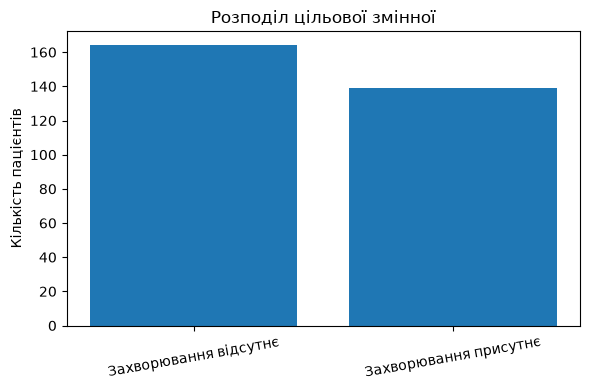

In [13]:
target_counts = df["target"].value_counts().sort_index()

print(target_counts)

plt.figure(figsize=(6, 4))
plt.bar(
    ["Захворювання відсутнє", "Захворювання присутнє"],
    target_counts.values
)
plt.title("Розподіл цільової змінної")
plt.ylabel("Кількість пацієнтів")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

### 14. Аналіз розподілу віку

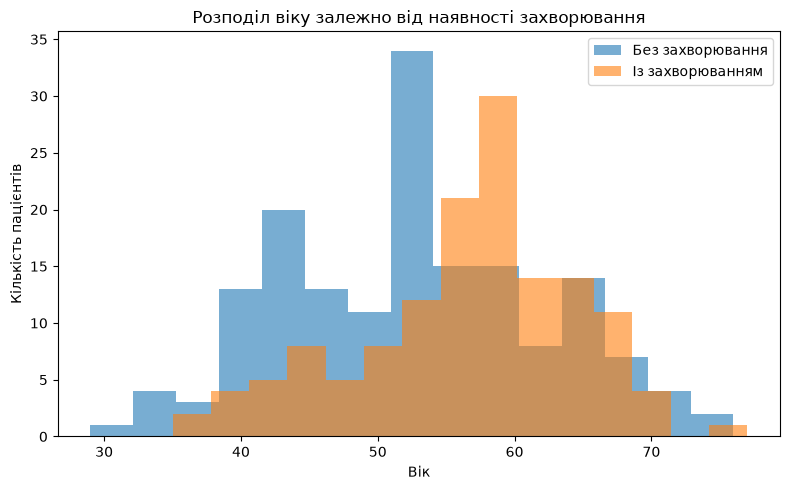

In [14]:
plt.figure(figsize=(8, 5))

plt.hist(
    df[df["target"] == 0]["age"],
    bins=15,
    alpha=0.6,
    label="Без захворювання"
)

plt.hist(
    df[df["target"] == 1]["age"],
    bins=15,
    alpha=0.6,
    label="Із захворюванням"
)

plt.xlabel("Вік")
plt.ylabel("Кількість пацієнтів")
plt.title("Розподіл віку залежно від наявності захворювання")
plt.legend()
plt.tight_layout()
plt.show()

### 15. Аналіз захворювання залежно від статі

target   0    1
sex            
0       72   25
1       92  114


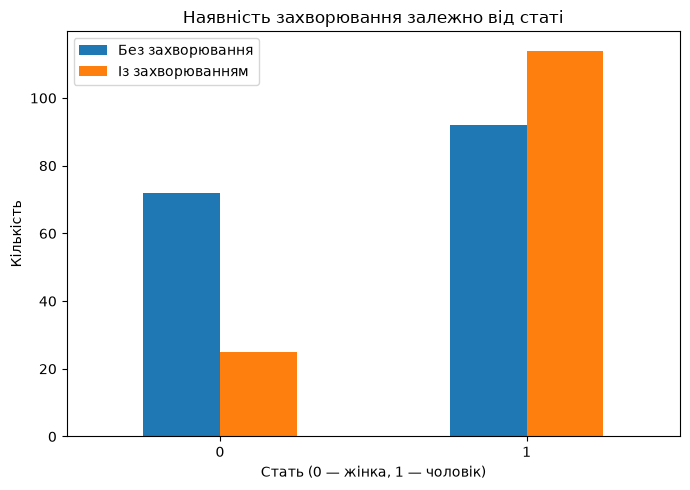

In [15]:
sex_target = pd.crosstab(df["sex"], df["target"])

print(sex_target)

sex_target.plot(kind="bar", figsize=(7, 5))

plt.title("Наявність захворювання залежно від статі")
plt.xlabel("Стать (0 — жінка, 1 — чоловік)")
plt.ylabel("Кількість")
plt.legend(["Без захворювання", "Із захворюванням"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 16. Аналіз захворювання залежно від типу болю у грудях

target   0    1
cp             
1       16    7
2       41    9
3       68   18
4       39  105


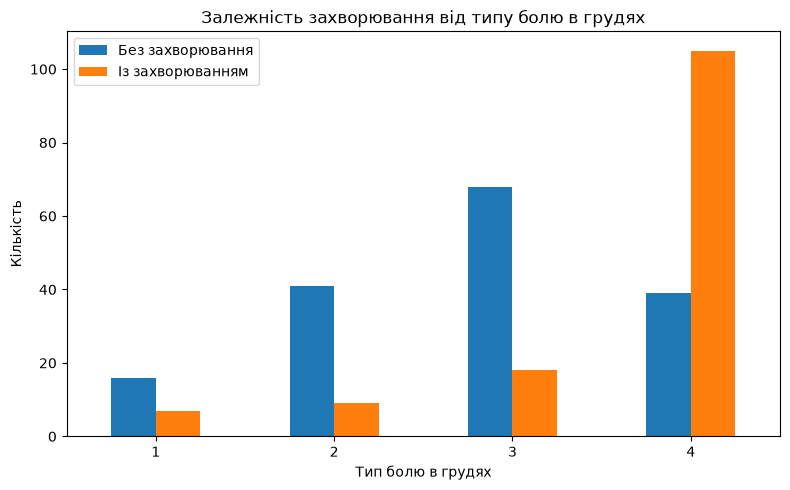

In [16]:
cp_target = pd.crosstab(df["cp"], df["target"])

print(cp_target)

cp_target.plot(kind="bar", figsize=(8, 5))

plt.title("Залежність захворювання від типу болю в грудях")
plt.xlabel("Тип болю в грудях")
plt.ylabel("Кількість")
plt.legend(["Без захворювання", "Із захворюванням"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 17. Аналіз артеріального тиску

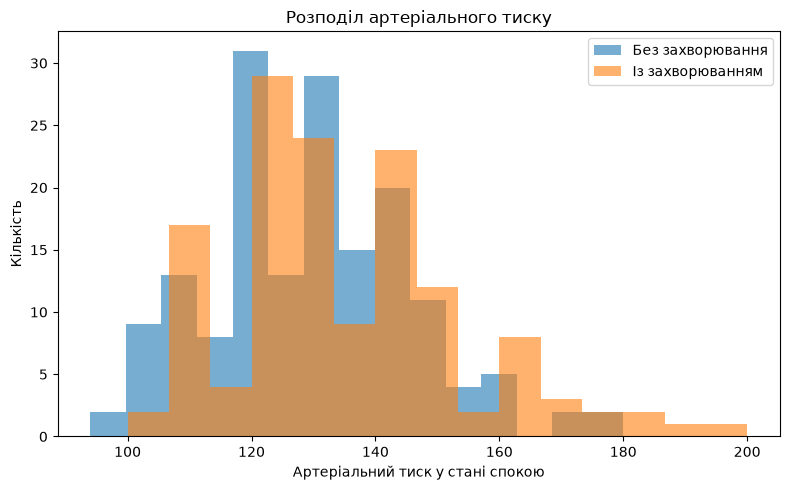

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(
    df[df["target"] == 0]["trestbps"].dropna(),
    bins=15,
    alpha=0.6,
    label="Без захворювання"
)

plt.hist(
    df[df["target"] == 1]["trestbps"].dropna(),
    bins=15,
    alpha=0.6,
    label="Із захворюванням"
)

plt.xlabel("Артеріальний тиск у стані спокою")
plt.ylabel("Кількість")
plt.title("Розподіл артеріального тиску")
plt.legend()
plt.tight_layout()
plt.show()

### 18. Аналіз рівня холестерину

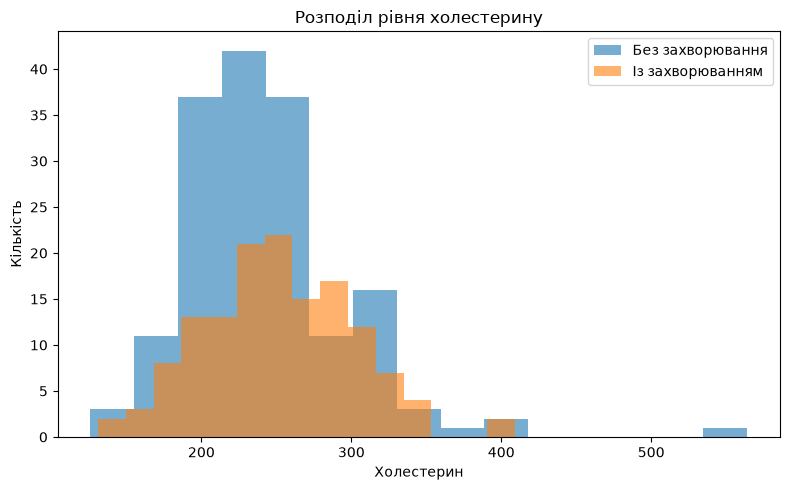

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(
    df[df["target"] == 0]["chol"].dropna(),
    bins=15,
    alpha=0.6,
    label="Без захворювання"
)

plt.hist(
    df[df["target"] == 1]["chol"].dropna(),
    bins=15,
    alpha=0.6,
    label="Із захворюванням"
)

plt.xlabel("Холестерин")
plt.ylabel("Кількість")
plt.title("Розподіл рівня холестерину")
plt.legend()
plt.tight_layout()
plt.show()

### 19. Аналіз максимальної частоти серцевих скорочень

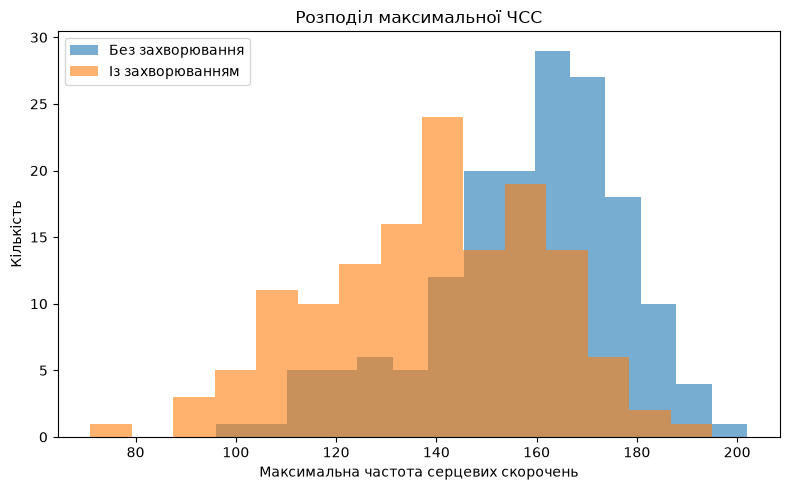

In [19]:
plt.figure(figsize=(8, 5))

plt.hist(
    df[df["target"] == 0]["thalach"].dropna(),
    bins=15,
    alpha=0.6,
    label="Без захворювання"
)

plt.hist(
    df[df["target"] == 1]["thalach"].dropna(),
    bins=15,
    alpha=0.6,
    label="Із захворюванням"
)

plt.xlabel("Максимальна частота серцевих скорочень")
plt.ylabel("Кількість")
plt.title("Розподіл максимальної ЧСС")
plt.legend()
plt.tight_layout()
plt.show()

### 20. Розрахунок кореляції ознак із цільовою змінною

In [20]:
correlation = df.corr(numeric_only=True)

target_correlation = (
    correlation["target"]
    .drop("target")
    .sort_values()
)

print("Кореляція ознак із цільовою змінною:")
print(target_correlation)

Кореляція ознак із цільовою змінною:
thalach    -0.417167
fbs         0.025264
chol        0.085164
trestbps    0.150825
restecg     0.169202
age         0.223120
sex         0.276816
slope       0.339213
cp          0.414446
oldpeak     0.424510
exang       0.431894
ca          0.460442
thal        0.525689
Name: target, dtype: float64


### 21. Візуалізація кореляції ознак

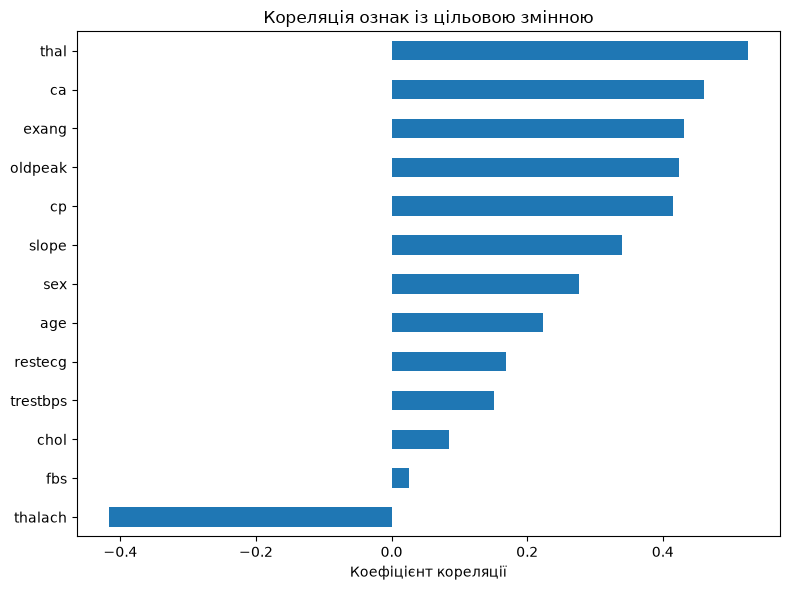

In [21]:
plt.figure(figsize=(8, 6))

target_correlation.plot(kind="barh")

plt.title("Кореляція ознак із цільовою змінною")
plt.xlabel("Коефіцієнт кореляції")
plt.tight_layout()
plt.show()

### 22. Перевірка числових ознак на можливі аномальні значення

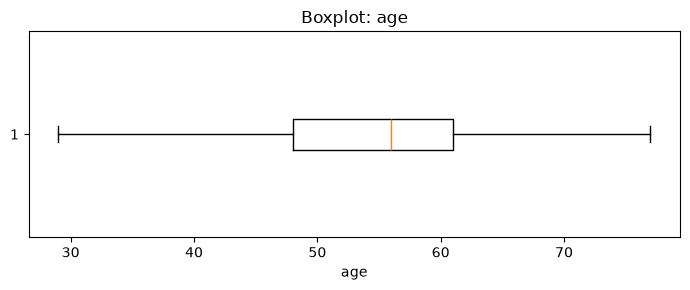

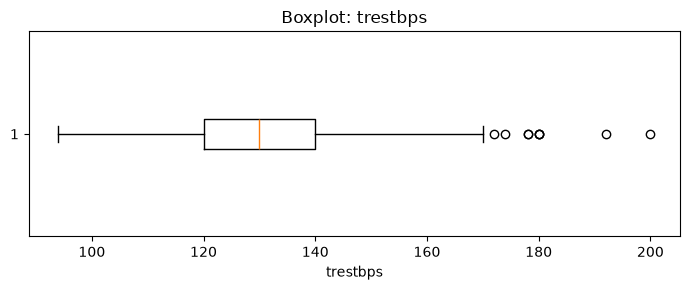

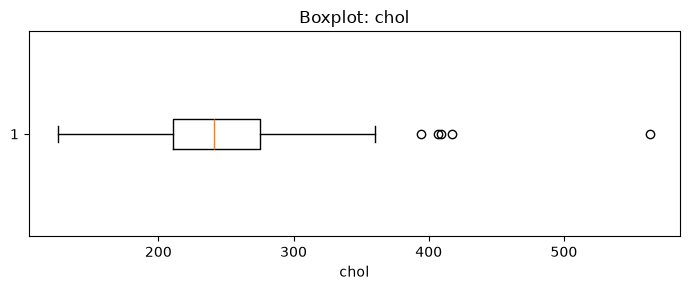

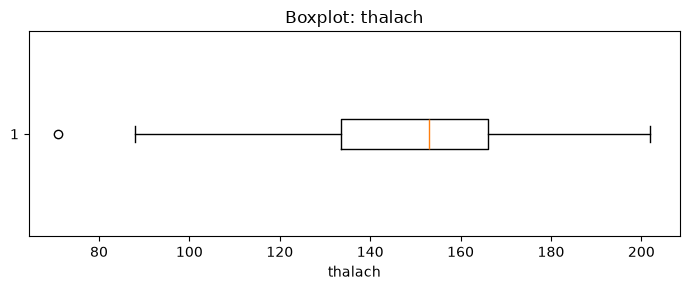

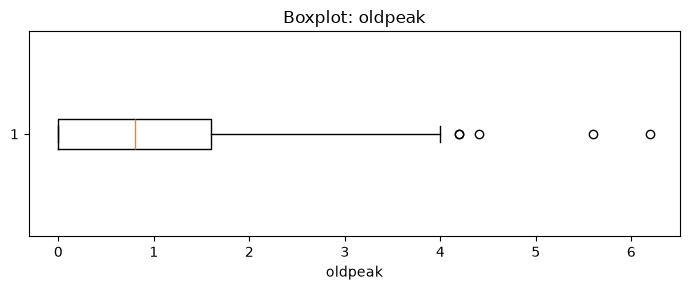

In [22]:
continuous_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

for feature in continuous_features:
    plt.figure(figsize=(7, 3))
    plt.boxplot(df[feature].dropna(), vert=False)
    plt.title(f"Boxplot: {feature}")
    plt.xlabel(feature)
    plt.tight_layout()
    plt.show()

## Підготовка даних

На цьому етапі дані поділяються на тренувальну та тестову вибірки. Для запобігання витоку інформації обробка пропущених значень, масштабування та кодування категоріальних ознак виконуються всередині Pipeline після поділу даних.

Для числових ознак використовується заповнення пропусків медіаною та StandardScaler. Для категоріальних ознак пропуски заповнюються найбільш частим значенням та використовується OneHotEncoder.

### 23. Визначення числових і категоріальних ознак

In [23]:
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

numeric_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

print("Числові ознаки:")
print(numeric_features)

print("\nКатегоріальні ознаки:")
print(categorical_features)

Числові ознаки:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Категоріальні ознаки:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


### 24. Розділення даних на тренувальну та тестову вибірки

In [24]:
X_model = df.drop(columns=["target"])
y_model = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_model
)

print("Розмір тренувальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

print("\nРозподіл класів у тренувальній вибірці:")
print(y_train.value_counts(normalize=True))

print("\nРозподіл класів у тестовій вибірці:")
print(y_test.value_counts(normalize=True))

Розмір тренувальної вибірки: (242, 13)
Розмір тестової вибірки: (61, 13)

Розподіл класів у тренувальній вибірці:
target
0    0.541322
1    0.458678
Name: proportion, dtype: float64

Розподіл класів у тестовій вибірці:
target
0    0.540984
1    0.459016
Name: proportion, dtype: float64


### 25. Підготовка числових ознак із масштабуванням

In [25]:
numeric_transformer_scaled = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

### 26. Підготовка категоріальних ознак

In [26]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

### 27. Формування preprocessing pipeline для Logistic Regression та SVM

In [27]:
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_scaled, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

### 28. Формування preprocessing pipeline для Random Forest

In [28]:
numeric_transformer_unscaled = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_unscaled, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

### 29. Навчання моделі Logistic Regression

In [29]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_scaled),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=RANDOM_STATE
            )
        )
    ]
)

logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression навчена.")

Logistic Regression навчена.


### 30. Навчання моделі SVM

In [30]:
svm_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_scaled),
        (
            "classifier",
            SVC(
                kernel="rbf",
                probability=True,
                random_state=RANDOM_STATE
            )
        )
    ]
)

svm_pipeline.fit(X_train, y_train)

print("SVM навчена.")

SVM навчена.


### 31. Навчання моделі Random Forest

In [31]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_unscaled),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=RANDOM_STATE
            )
        )
    ]
)

rf_pipeline.fit(X_train, y_train)

print("Random Forest навчений.")

Random Forest навчений.


### 32. Створення функції для оцінювання моделей

In [32]:
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "True Negative": tn,
        "False Positive": fp,
        "False Negative": fn,
        "True Positive": tp
    }

    return metrics, y_pred, y_prob

### 33. Оцінювання всіх моделей

In [33]:
models = {
    "Logistic Regression": logistic_pipeline,
    "SVM": svm_pipeline,
    "Random Forest": rf_pipeline
}

results = []
predictions = {}
probabilities = {}

for model_name, model in models.items():
    metrics, y_pred, y_prob = evaluate_model(
        model_name,
        model,
        X_test,
        y_test
    )

    results.append(metrics)
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,True Negative,False Positive,False Negative,True Positive
0,Logistic Regression,0.885246,0.83871,0.928571,0.881356,0.966450,28,5,2,26
1,SVM,0.885246,0.83871,0.928571,0.881356,0.964286,28,5,2,26
2,Random Forest,0.868852,0.81250,0.928571,0.866667,0.943723,27,6,2,26


### 34. Формування порівняльної таблиці метрик

In [34]:
metric_columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

comparison_table = results_df[metric_columns].copy()

for column in metric_columns[1:]:
    comparison_table[column] = comparison_table[column].round(4)

comparison_table

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8852,0.8387,0.9286,0.8814,0.9665
1,SVM,0.8852,0.8387,0.9286,0.8814,0.9643
2,Random Forest,0.8689,0.8125,0.9286,0.8667,0.9437


### Порівняння результатів

Найвищу загальну точність показали Logistic Regression та SVM — приблизно 88,52%. Обидві моделі також мають Recall 92,86%, тобто правильно виявляють більшість пацієнтів із захворюванням.

Random Forest має дещо нижчі Accuracy, Precision, F1-Score та ROC-AUC.

За основними метриками Logistic Regression і SVM показали практично однакові результати, однак Logistic Regression має найбільше значення ROC-AUC — приблизно 0,9665. Тому за сукупністю метрик саме її обрано як найкращу модель.

### 35. Візуальне порівняння моделей

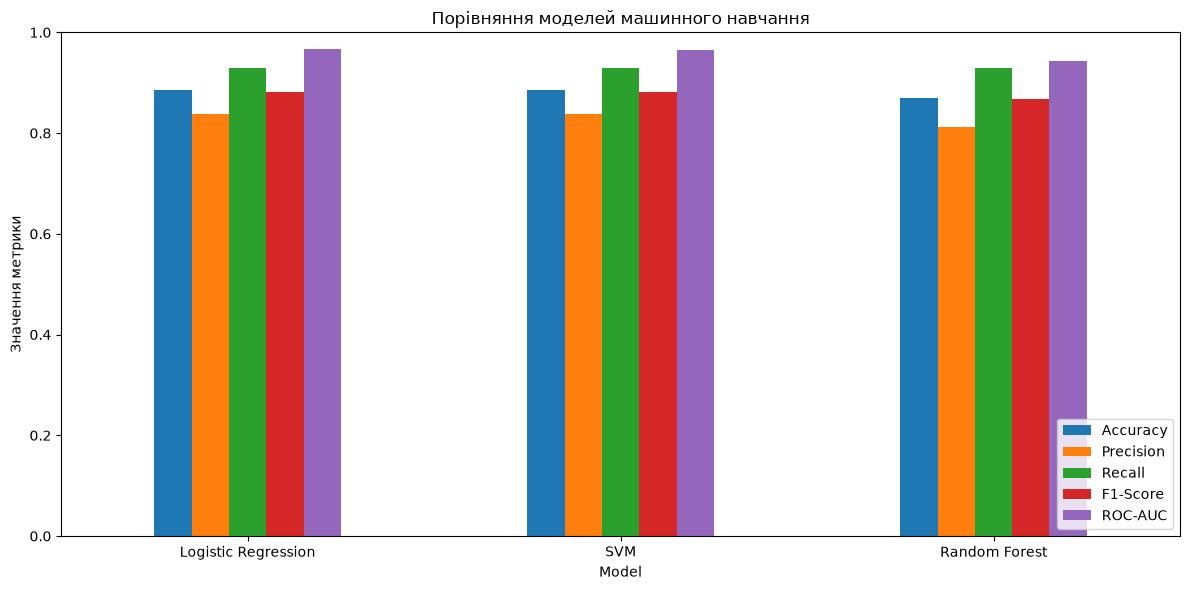

In [35]:
comparison_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.ylim(0, 1)
plt.ylabel("Значення метрики")
plt.title("Порівняння моделей машинного навчання")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 36. Побудова матриць плутанини

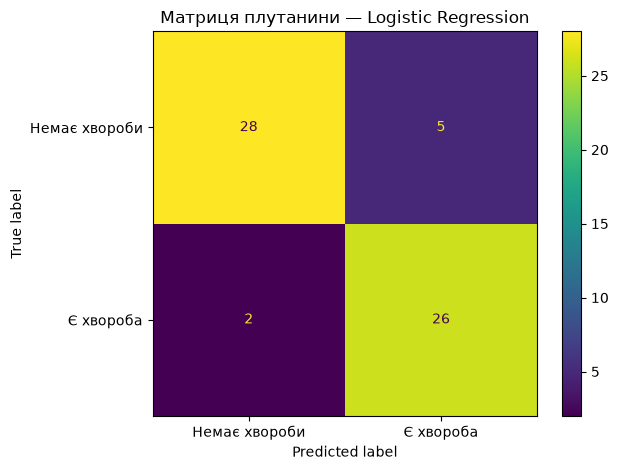

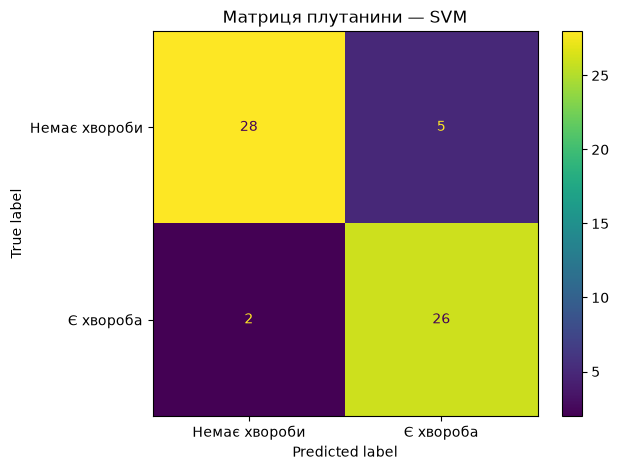

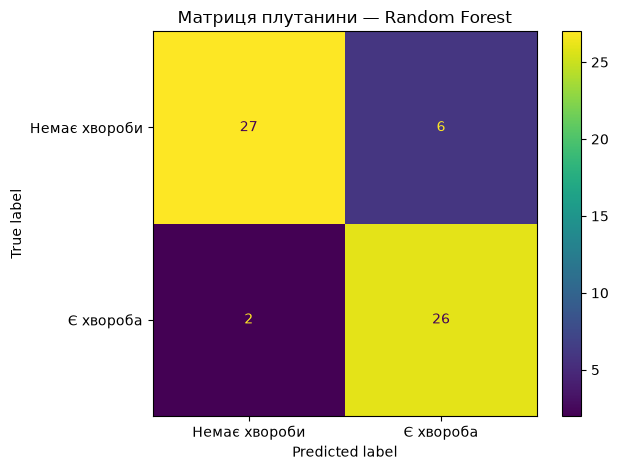

In [36]:
for model_name in models.keys():
    cm = confusion_matrix(
        y_test,
        predictions[model_name]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Немає хвороби", "Є хвороба"]
    )

    disp.plot()
    plt.title(f"Матриця плутанини — {model_name}")
    plt.tight_layout()
    plt.show()

### 37. Аналіз False Negative та Recall

In [37]:
fn_table = results_df[
    ["Model", "False Negative", "Recall"]
].copy()

fn_table["Recall"] = fn_table["Recall"].round(4)

fn_table.sort_values(
    by=["False Negative", "Recall"],
    ascending=[True, False]
)

,Model,False Negative,Recall
0,Logistic Regression,2,0.9286
1,SVM,2,0.9286
2,Random Forest,2,0.9286


### 38. Формування Classification Report

In [38]:
for model_name in models.keys():
    print("=" * 70)
    print(model_name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions[model_name],
            target_names=[
                "Без захворювання",
                "Із захворюванням"
            ]
        )
    )

Logistic Regression
                  precision    recall  f1-score   support

Без захворювання       0.93      0.85      0.89        33
Із захворюванням       0.84      0.93      0.88        28

        accuracy                           0.89        61
       macro avg       0.89      0.89      0.89        61
    weighted avg       0.89      0.89      0.89        61

SVM
                  precision    recall  f1-score   support

Без захворювання       0.93      0.85      0.89        33
Із захворюванням       0.84      0.93      0.88        28

        accuracy                           0.89        61
       macro avg       0.89      0.89      0.89        61
    weighted avg       0.89      0.89      0.89        61

Random Forest
                  precision    recall  f1-score   support

Без захворювання       0.93      0.82      0.87        33
Із захворюванням       0.81      0.93      0.87        28

        accuracy                           0.87        61
       macro avg       0.8

### 39. Побудова ROC-кривих

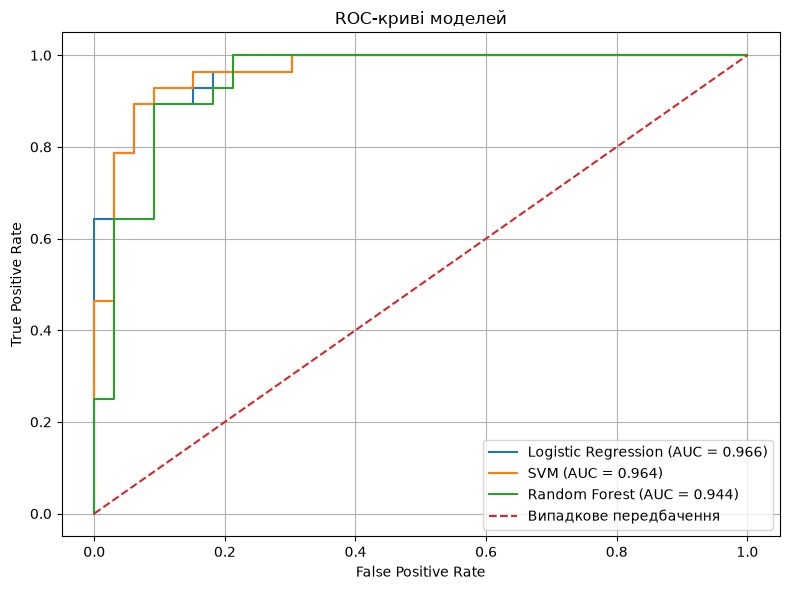

In [39]:
plt.figure(figsize=(8, 6))

for model_name in models.keys():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities[model_name]
    )

    auc = roc_auc_score(
        y_test,
        probabilities[model_name]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Випадкове передбачення"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-криві моделей")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### 40. Ранжування моделей за якістю

In [40]:
ranking = results_df.sort_values(
    by=["Recall", "F1-Score", "ROC-AUC"],
    ascending=False
).reset_index(drop=True)

ranking[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "False Negative"
    ]
]

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,False Negative
0,Logistic Regression,0.885246,0.83871,0.928571,0.881356,0.966450,2
1,SVM,0.885246,0.83871,0.928571,0.881356,0.964286,2
2,Random Forest,0.868852,0.81250,0.928571,0.866667,0.943723,2


### 41. Вибір найкращої моделі

In [41]:
best_model_name = ranking.loc[0, "Model"]

best_model = models[best_model_name]

print("Обрана найкраща модель:")
print(best_model_name)

Обрана найкраща модель:
Logistic Regression


### 42. Збереження найкращої моделі

In [42]:
os.makedirs("../models", exist_ok=True)

model_path = "../models/best_heart_disease_model.joblib"

joblib.dump(
    best_model,
    model_path
)

print("Модель збережено:")
print(model_path)

Модель збережено:
../models/best_heart_disease_model.joblib


### 43. Збереження інформації про модель

In [43]:
best_row = ranking.iloc[0]

model_info = {
    "model_name": best_model_name,
    "accuracy": float(best_row["Accuracy"]),
    "precision": float(best_row["Precision"]),
    "recall": float(best_row["Recall"]),
    "f1_score": float(best_row["F1-Score"]),
    "roc_auc": float(best_row["ROC-AUC"]),
    "false_negative": int(best_row["False Negative"]),
    "feature_order": X_model.columns.tolist()
}

with open(
    "../models/model_info.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        model_info,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Інформацію про модель збережено.")

Інформацію про модель збережено.


### 44. Перевірка завантаження збереженої моделі

In [44]:
loaded_model = joblib.load(
    "../models/best_heart_disease_model.joblib"
)

test_predictions = loaded_model.predict(X_test)

print(
    "Accuracy завантаженої моделі:",
    accuracy_score(
        y_test,
        test_predictions
    )
)

Accuracy завантаженої моделі: 0.8852459016393442


## Висновок до експериментальної частини

У роботі було проведено повний цикл побудови системи машинного навчання для бінарної класифікації ризику серцевого захворювання.

Було виконано дослідницький аналіз набору даних UCI Heart Disease, перевірено пропущені значення та можливі аномальні спостереження, виконано підготовку числових і категоріальних ознак.

Було реалізовано три різні алгоритми класифікації:

- Logistic Regression;
- Support Vector Machine;
- Random Forest.

Моделі порівнювалися за Accuracy, Precision, Recall, F1-Score та ROC-AUC. Додатково було проаналізовано матриці плутанини та кількість False Negative.

У зв'язку з медичним характером задачі особлива увага приділялася Recall, оскільки хибно-негативний прогноз означає, що модель не виявила захворювання в пацієнта, у якого воно фактично присутнє.

На основі результатів порівняння було обрано найкращу модель та збережено її для подальшого практичного використання.